# IRWA 2026 Part 1: Text Processing and Exploratory Data Analysis

**Corpus:** `fashion_products_dataset.json` (e-commerce fashion products).
**Goal of this part:** prepare the documents for indexing (Part 2) and describe the dataset.

The structure follows the Part 1 statement:

0. Setup and data loading
1. **PART 1 – Data preparation**
   - 1.1 Text pre-processing (title, description)
     - 1.1.1 Removing stop words · 1.1.2 Tokenization · 1.1.3 Removing punctuation marks · 1.1.4 Stemming · 1.1.5 Anything else (bonus) · 1.1.6 Full pipeline
   - 1.2 Fields returned for every result
   - 1.3 category, sub_category, brand, product_details and seller
   - 1.4 out_of_stock, selling_price, discount, actual_price, average_rating
   - Hints: 1 `validation_labels.csv` · 2 NLTK · 3 keep `pid` (and save the processed corpus)
2. **PART 2 – Exploratory Data Analysis**
   - 2.1 Word counting distribution · 2.2 Average sentence length · 2.3 Vocabulary size ·
     2.4 Ranking of products by rating, price and discount · 2.5 Top sellers and brands ·
     2.6 Out-of-stock distribution · 2.7 Word clouds · 2.8 Entity recognition ·
     2.9 Other findings · 2.10 Summary

The functions live in `myapp/search/preprocessing.py`, numbered with the same points (1.1–1.4),
so that Parts 2–4 apply exactly the same processing to the queries.

## 0. Setup and data loading

In [1]:
import sys, re, html, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The notebook runs from project_progress/part_1/, so the repo root is two folders up
ROOT = Path("../..").resolve()
sys.path.append(str(ROOT))          # so Python can find myapp/

DATA_PATH = ROOT / "data" / "fashion_products_dataset.json"
LABELS_PATH = ROOT / "data" / "validation_labels.csv"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

from myapp.search.preprocessing import (
    STOP_WORDS, remove_stopwords, tokenize, stem, normalize_text, preprocess_text,   # 1.1
    OUTPUT_FIELDS,                                                                   # 1.2
    USEFUL_DETAIL_KEYS, details_to_dict,                                             # 1.3
    to_number,                                                                       # 1.4
    load_raw_corpus, build_processed_corpus)

def savefig(name):
    """Save the current figure into part_1/figures (for the report)."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=130)
    plt.show()

In [2]:
raw = load_raw_corpus(DATA_PATH)
print(raw.shape)
raw.head(3)

(28080, 17)


,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:51,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,66% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...


In [3]:
# Missing values: empty strings / empty lists count as missing
def is_missing(v):
    return v is None or (isinstance(v, float) and np.isnan(v)) or (isinstance(v, (str, list)) and len(v) == 0)

missing = raw.apply(lambda col: col.map(is_missing).sum()).sort_values(ascending=False)
missing_pct = (missing / len(raw) * 100).round(1)
pd.DataFrame({"missing": missing, "%": missing_pct})

,missing,%
description,11150,39.7
average_rating,2261,8.1
brand,2009,7.2
seller,1643,5.9
discount,855,3.0
actual_price,777,2.8
images,772,2.7
selling_price,2,0.0
_id,0,0.0
crawled_at,0,0.0


## PART 1 – Data preparation

### 1.1 Text pre-processing (title, description)

The statement asks for: removing stop words, tokenization, removing punctuation marks, stemming,
and anything else needed (bonus). Each step has its own function in `preprocessing.py` (section 1.1)
and is shown below on the description of the first product.

Note: the subsections follow the order of the statement, but the steps are **executed** in this order:
*anything else (normalize) → tokenization → remove punctuation → remove stop words → stemming*
(stop words can only be removed once the text is split into tokens). See 1.1.6.

In [4]:
example = raw.iloc[0]
text = example["description"]
print(text)

Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India


#### 1.1.1 Removing stop words
We use the NLTK English stop word list (`STOP_WORDS`). `remove_stopwords()` also drops 1-letter leftovers
such as the *s* of *men's* (numbers are kept: sizes, "pack of 2", "100% cotton").

In [5]:
print(len(STOP_WORDS), "stop words, e.g.:", sorted(STOP_WORDS)[:20])

tokens = tokenize(normalize_text(text))          # stop words are removed from tokens
no_stop = remove_stopwords(tokens)
print("\nBefore:", tokens)
print("After :", no_stop)
print("Removed:", [t for t in tokens if t not in no_stop])

198 stop words, e.g.: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been']

Before: ['yorker', 'trackpants', 'made', 'from', '100', 'rich', 'combed', 'cotton', 'giving', 'it', 'a', 'rich', 'look', 'designed', 'for', 'comfort', 'skin', 'friendly', 'fabric', 'itch', 'free', 'waistband', 'great', 'for', 'all', 'year', 'round', 'use', 'proudly', 'made', 'in', 'india']
After : ['yorker', 'trackpants', 'made', '100', 'rich', 'combed', 'cotton', 'giving', 'rich', 'look', 'designed', 'comfort', 'skin', 'friendly', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proudly', 'made', 'india']
Removed: ['from', 'it', 'a', 'for', 'for', 'all', 'in']


#### 1.1.2 Tokenization
NLTK `word_tokenize` splits the text into tokens. Punctuation marks are still separate tokens at this point.

In [6]:
from nltk.tokenize import word_tokenize
print(word_tokenize(normalize_text(text)))

['yorker', 'trackpants', 'made', 'from', '100', '%', 'rich', 'combed', 'cotton', 'giving', 'it', 'a', 'rich', 'look', '.', 'designed', 'for', 'comfort', ',', 'skin', 'friendly', 'fabric', ',', 'itch', 'free', 'waistband', '&', 'great', 'for', 'all', 'year', 'round', 'use', 'proudly', 'made', 'in', 'india']


#### 1.1.3 Removing punctuation marks
`tokenize()` = `word_tokenize` + remove every character that is not a letter or a digit
(`100%` → `100`, `,` and `.` disappear).

In [7]:
nltk_tokens = word_tokenize(normalize_text(text))
clean_tokens = tokenize(normalize_text(text))
print(clean_tokens)
print("Punctuation tokens removed:", [t for t in nltk_tokens if not any(ch.isalnum() for ch in t)])

['yorker', 'trackpants', 'made', 'from', '100', 'rich', 'combed', 'cotton', 'giving', 'it', 'a', 'rich', 'look', 'designed', 'for', 'comfort', 'skin', 'friendly', 'fabric', 'itch', 'free', 'waistband', 'great', 'for', 'all', 'year', 'round', 'use', 'proudly', 'made', 'in', 'india']
Punctuation tokens removed: ['%', '.', ',', ',', '&']


#### 1.1.4 Stemming
Snowball (Porter2) stemmer: groups variants of a word into the same term
(`sleeves` → `sleev`, `jeans` → `jean`, `designed` → `design`).

In [8]:
for word in no_stop:
    if stem(word) != word:
        print(f"{word:12} -> {stem(word)}")

trackpants   -> trackpant
combed       -> comb
giving       -> give
designed     -> design
friendly     -> friend
proudly      -> proud


#### 1.1.5 Anything else (bonus)
`normalize_text()` cleans the raw text before tokenization:

| Step | Example | Why |
|---|---|---|
| HTML entities and tags, URLs | `&amp;` → `&`, drops `<b>` | noise found in some descriptions |
| Split `/` and literal `\n` | `Calf/Crew` → `Calf Crew` | words joined by a slash |
| Unicode → ASCII | `‘OKANE’` → `'OKANE'` | same term with different quote characters |
| Split glued punctuation | `cotton.Designed` → `cotton. Designed` | ~1,200 descriptions have words glued by `.` or `,` |
| Unify *t-shirt* | `T-Shirt`, `t shirt`, `tshirts` → `tshirt` | very frequent product type written many ways |
| Lowercase | `Cotton` → `cotton` | case is not informative for retrieval |
| Split hyphenated words | `full-sleeve` → `full sleeve` | matches queries written without hyphen |

In [9]:
print(normalize_text(text))

yorker trackpants made from 100% rich combed cotton giving it a rich look. designed for comfort, skin friendly fabric, itch free waistband & great for all year round use proudly made in india


In [10]:
# Effect of each extra normalization step
for s in ["Men's T-Shirt", "full-sleeve t shirts", "rich look.Designed for Comfort,Skin friendly",
          "‘OKANE’ endeavors", "100% Cotton &amp; Lycra"]:
    print(f"{s!r:50} -> {preprocess_text(s)}")

"Men's T-Shirt"                                    -> ['men', 'tshirt']
'full-sleeve t shirts'                             -> ['full', 'sleev', 'tshirt']
'rich look.Designed for Comfort,Skin friendly'     -> ['rich', 'look', 'design', 'comfort', 'skin', 'friend']
'‘OKANE’ endeavors'                                -> ['okan', 'endeavor']
'100% Cotton &amp; Lycra'                          -> ['100', 'cotton', 'lycra']


#### 1.1.6 Full pipeline
`preprocess_text()` = normalize (1.1.5) → tokenize (1.1.2) + remove punctuation (1.1.3) → remove stop words (1.1.1) → stem (1.1.4).
It is applied to title and description of every product (in 1.4, `build_processed_corpus`), and
in Part 2 it must be applied to the queries too.

In [11]:
example = raw.iloc[0]
print("RAW TITLE      :", example["title"])
print("PROCESSED TITLE:", preprocess_text(example["title"]))
print()
print("RAW DESCRIPTION      :", example["description"])
print("PROCESSED DESCRIPTION:", preprocess_text(example["description"]))

RAW TITLE      : Solid Women Multicolor Track Pants
PROCESSED TITLE: ['solid', 'women', 'multicolor', 'track', 'pant']

RAW DESCRIPTION      : Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India
PROCESSED DESCRIPTION: ['yorker', 'trackpant', 'made', '100', 'rich', 'comb', 'cotton', 'give', 'rich', 'look', 'design', 'comfort', 'skin', 'friend', 'fabric', 'itch', 'free', 'waistband', 'great', 'year', 'round', 'use', 'proud', 'made', 'india']


In [12]:
# The two validation queries go through the same pipeline
for q in ["women full sleeve sweatshirt cotton", "men slim jeans blue"]:
    print(q, "->", preprocess_text(q))

women full sleeve sweatshirt cotton -> ['women', 'full', 'sleev', 'sweatshirt', 'cotton']
men slim jeans blue -> ['men', 'slim', 'jean', 'blue']


### 1.2 Fields returned for every result

For future queries every result must return (when present):
`pid, title, description, brand, category, sub_category, product_details, seller, out_of_stock,
selling_price, discount, actual_price, average_rating, url`.

We therefore keep these **original** fields untouched in the processed corpus (for display) and
add new `*_tokens` columns for indexing. `pid` is kept as the document identifier (it is unique,
28,080 values) because it is used in `validation_labels.csv`. `_id`, `images` and `crawled_at` are not
needed for retrieval.

In [13]:
# All the fields a search result must return are present in the dataset
print("Missing fields:", [f for f in OUTPUT_FIELDS if f not in raw.columns])   # [] = none missing
raw[OUTPUT_FIELDS].head(3)

Missing fields: []


,pid,title,description,brand,category,sub_category,product_details,seller,out_of_stock,selling_price,discount,actual_price,average_rating,url
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,False,921,69% off,"2,999",3.9,https://www.flipkart.com/yorker-solid-men-mult...
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,False,499,66% off,"1,499",3.9,https://www.flipkart.com/yorker-solid-men-blue...
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,Yorker trackpants made from 100% rich combed c...,York,Clothing and Accessories,Bottomwear,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,False,931,68% off,"2,999",3.9,https://www.flipkart.com/yorker-solid-men-mult...


### 1.3 category, sub_category, brand, product_details and seller

Options:

| Approach | Pros | Cons |
|---|---|---|
| **Merge into one text field** | simple index, one vocabulary; a query term matches wherever it appears | loses *where* the term occurred; a brand word in the description counts the same as in `brand`; long fields dominate |
| **Separate fields in the index** | allows field weighting (e.g. title × 3) and field-specific filters (brand = Levi's) | bigger/more complex index, ranking must combine fields |
| **Use as filters / facets only** (not text) | exact, cheap; good for `category` (only 4 values) | user query words like "cotton" or "slim" would not match at all |

What the data tells us:
* `category` has only **4 values** (96.6 % "Clothing and Accessories") → almost no discriminative power as text.
* `sub_category` has 24 values, some polluted with seller names ("Uber Urban Clothing and Accessories").
* `brand` is often **truncated** ("Lev", "ECKO Unl", "Pu"); `seller` often contains the full name.
* `product_details` contains the attributes users search for (Fabric, Color, Fit, Sleeve, Ideal For),
  but also codes and boiler-plate (Style Code, Fabric Care, Country of Origin).

**Our choice (hybrid):** we keep a separate token column for every field **and** an `all_tokens`
field = title + description + brand + category + sub_category + useful product_details values.
Part 2 can start with the simple merged index, and Part 3 can use the separate fields for weighting.
`seller` is kept as its own field but *not* merged (it is a shop name, users rarely search for it).
From `product_details` only the values of `USEFUL_DETAIL_KEYS` are indexed.

> ✏️ *Group: discuss and adapt this choice; justify it in the report in your own words.*

In [14]:
detail_keys = collections.Counter(k for d in raw["product_details"] for item in d for k in item)
print("Distinct product_details keys:", len(detail_keys))
pd.Series(detail_keys).sort_values(ascending=False).head(25)

Distinct product_details keys: 127


Fabric               25959
Style Code           25763
Pattern              25692
Fabric Care          21830
Suitable For         19139
Sleeve               18861
Pack of              17953
Type                 17394
Ideal For            16983
Fit                  16808
Reversible           14471
Color                14185
Brand Color          12841
Sales Package        12518
Generic Name         12274
Size                 12251
Neck Type            12240
Country of Origin    11659
Brand Fit             7747
Sleeve Type           6207
Other Details         5181
Model Name            5104
Occasion              4371
Closure               4257
Secondary Color       3026
dtype: int64

In [15]:
print("Useful keys used for indexing:", USEFUL_DETAIL_KEYS)
print()
print(details_to_dict(raw.iloc[0]["product_details"]))

Useful keys used for indexing: ['Fabric', 'Pattern', 'Sleeve', 'Sleeve Type', 'Type', 'Ideal For', 'Fit', 'Brand Fit', 'Color', 'Brand Color', 'Secondary Color', 'Neck Type', 'Neck', 'Occasion', 'Closure', 'Collar', 'Hooded', 'Generic Name', 'Suitable For', 'Pockets', 'Rise', 'Length', 'Fabric Type', 'Pack of']

{'Style Code': '1005COMBO2', 'Closure': 'Elastic', 'Pockets': 'Side Pockets', 'Fabric': 'Cotton Blend', 'Pattern': 'Solid', 'Color': 'Multicolor'}


### 1.4 out_of_stock, selling_price, discount, actual_price, average_rating

These should **not** be indexed as textual terms: a token "921" or "69" has no meaning for a text
query and would only grow the vocabulary. They are converted to numbers and stored as document
attributes, to be used later for **filtering** (e.g. hide out-of-stock, price < 500) and as
**ranking signals** (rating, discount) in Part 3.

Conversions:
* `"2,999"` → `2999.0`, `"69% off"` → `69.0`, `"3.9"` → `3.9`, `out_of_stock` → bool
* missing `average_rating` stays `NaN` (+ flag `has_rating`) – we do not invent a rating
* missing `actual_price` → equals `selling_price`, missing `discount` → 0 (no discount shown)

`to_number()` (section 1.4 of `preprocessing.py`) does the conversion. Finally `build_processed_corpus()`
applies 1.1, 1.3 and 1.4 to all 28,080 products.

In [16]:
for v in ["2,999", "69% off", "3.9", ""]:
    print(repr(v), "->", to_number(v))

'2,999' -> 2999.0
'69% off' -> 69.0
'3.9' -> 3.9
'' -> nan


In [17]:
import time
start = time.time()
corpus = build_processed_corpus(raw)
print(f"Processed in {time.time() - start:.1f} s")
corpus[["pid", "title", "selling_price", "actual_price", "discount", "average_rating",
        "out_of_stock", "title_tokens", "details_tokens"]].head()

Processed in 26.0 s


,pid,title,selling_price,actual_price,discount,average_rating,out_of_stock,title_tokens,details_tokens
0,TKPFCZ9EA7H5FYZH,Solid Women Multicolor Track Pants,921.0,2999.0,69.0,3.9,False,"[solid, women, multicolor, track, pant]","[cotton, blend, solid, multicolor, elast, side..."
1,TKPFCZ9EJZV2UVRZ,Solid Men Blue Track Pants,499.0,1499.0,66.0,3.9,False,"[solid, men, blue, track, pant]","[cotton, blend, solid, blue, drawstr, elast, s..."
2,TKPFCZ9EHFCY5Z4Y,Solid Men Multicolor Track Pants,931.0,2999.0,68.0,3.9,False,"[solid, men, multicolor, track, pant]","[cotton, blend, solid, multicolor, elast, side..."
3,TKPFCZ9ESZZ7YWEF,Solid Women Multicolor Track Pants,911.0,2999.0,69.0,3.9,False,"[solid, women, multicolor, track, pant]","[cotton, blend, solid, multicolor, elast, side..."
4,TKPFCZ9EVXKBSUD7,"Solid Women Brown, Grey Track Pants",943.0,2999.0,68.0,3.9,False,"[solid, women, brown, grey, track, pant]","[cotton, blend, solid, brown, grey, drawstr, e..."


In [18]:
corpus[["selling_price", "actual_price", "discount", "average_rating"]].describe().round(2)

,selling_price,actual_price,discount,average_rating
count,28078.00,28078.00,28080.00,25819.00
mean,705.64,1442.79,48.73,3.63
std,549.68,940.43,18.74,0.66
min,99.00,149.00,0.00,1.00
25%,390.00,849.00,37.00,3.20
50%,545.00,1199.00,52.00,3.80
75%,820.00,1799.00,62.00,4.10
max,7999.00,12999.00,87.00,5.00


## Hints from the statement

### Hint 1 – `validation_labels.csv`

The file has 40 labelled products for two queries:
`query_1 = "women full sleeve sweatshirt cotton"`, `query_2 = "men slim jeans blue"`.
For each query term we check in which field it appears, for relevant (1) vs non-relevant (0) documents.

In [19]:
labels = pd.read_csv(LABELS_PATH, dtype={"pid": str})
queries = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
val = labels.merge(corpus, on="pid", how="left", suffixes=("_label", ""))
print("Labelled docs found in corpus:", val["selling_price"].notna().sum(), "/", len(val))
print(labels.groupby(["query_id", "labels"]).size().unstack())

Labelled docs found in corpus: 40 / 40


labels     0   1
query_id        
1          7  13
2         10  10


In [20]:
fields = ["title_tokens", "description_tokens", "details_tokens", "sub_category_tokens", "brand_tokens"]
rows = []
for qid, q in queries.items():
    for term in preprocess_text(q):
        sub = val[val["query_id"] == qid]
        for lab in [1, 0]:
            s = sub[sub["labels"] == lab]
            row = {"query": qid, "term": term, "label": lab, "n_docs": len(s)}
            for f in fields:
                row[f.replace("_tokens", "")] = int(s[f].map(lambda toks: term in toks).sum())
            rows.append(row)
presence = pd.DataFrame(rows)
presence

,query,term,label,n_docs,title,description,details,sub_category,brand
0,1,women,1,13,13,6,0,0,0
1,1,women,0,7,7,2,4,0,0
2,1,full,1,13,13,6,13,0,0
3,1,full,0,7,3,4,3,0,0
4,1,sleev,1,13,13,5,13,0,0
5,1,sleev,0,7,3,5,7,0,0
6,1,sweatshirt,1,13,13,9,4,0,0
7,1,sweatshirt,0,7,3,4,0,0,0
8,1,cotton,1,13,0,12,7,0,0
9,1,cotton,0,7,0,7,6,0,0


In [21]:
# Look at the labelled documents themselves
pd.set_option("display.max_colwidth", 45)
val[["query_id", "labels", "title", "brand", "sub_category", "details_text", "out_of_stock", "average_rating"]]

,query_id,labels,title,brand,sub_category,details_text,out_of_stock,average_rating
0,1,1,Full Sleeve Printed Women Sweatshirt,CupidSto,Winter Wear,Cotton Blend Printed Full Sleeve Dark Blu...,False,3.2
1,1,0,Full Sleeve Striped Women Sweatshirt,REEB,Winter Wear,Polyester Blend Striped Full Sleeve Black...,False,4.0
2,1,1,Full Sleeve Printed Women Sweatshirt,Pu,Winter Wear,Cotton Blend Printed Full Sleeve Red Hood...,False,4.3
3,1,1,Full Sleeve Graphic Print Women Sweatshirt,Free Authori,Winter Wear,Polycotton Graphic Print Full Sleeve Yell...,False,3.9
4,1,0,Full Sleeve Solid Women Sweatshirt,Pu,Winter Wear,Cotton Blend Solid Full Sleeve Green High...,False,3.7
5,1,1,Full Sleeve Graphic Print Women Sweatshirt,Free Authori,Winter Wear,Polycotton Graphic Print Full Sleeve Red ...,False,3.9
6,1,0,Typography Women V Neck Multicolor T-Shir...,Free Authori,Topwear,Pure Cotton Typography Half Sleeve V Neck...,False,3.9
7,1,1,Full Sleeve Printed Women Sweatshirt,Pu,Winter Wear,Cotton Blend Printed Full Sleeve White Ho...,False,4.2
8,1,1,Full Sleeve Solid Women Sweatshirt,REEB,Winter Wear,Cotton Blend Solid Full Sleeve Black V-ne...,False,3.9
9,1,1,Full Sleeve Graphic Print Women Sweatshirt,Free Authori,Winter Wear,Polycotton Graphic Print Full Sleeve Red ...,False,3.9


**Observations (to verify and discuss in the report):**
* *cotton* mostly appears in `product_details` (Fabric) and the description – not in the title →
  indexing product_details values is necessary.
* *women / men* appear in the title, so title matching is important.
* Some labels are not explained by the text alone (e.g. women's jeans labelled relevant for
  "men slim jeans", some full-sleeve women sweatshirts labelled 0). Text fields cannot perfectly
  separate the classes – useful to keep in mind for evaluation in Part 2.

### Hint 2 – NLTK
NLTK is used for the stop word list (`stopwords`), the tokenizer (`word_tokenize`) and the stemmer
(`SnowballStemmer`), see 1.1.

### Hint 3 – Keep `pid`
`pid` is unique, so it is kept unchanged as the document identifier. The processed corpus is saved
with it for Part 2 (indexing and evaluation).

In [22]:
print("Unique pids:", raw["pid"].nunique(), "of", len(raw))

Unique pids: 28080 of 28080


In [23]:
OUT_PATH = ROOT / "data" / "processed_corpus.pkl"
corpus.to_pickle(OUT_PATH)
print("Saved", corpus.shape, "->", OUT_PATH)

Saved (28080, 28) -> /tmp/claude-0/r2/repo/data/processed_corpus.pkl


## PART 2 – Exploratory Data Analysis
The subsections follow the examples listed in the statement, in the same order.

### 2.1 Word counting distribution

In [24]:
corpus["title_words_raw"] = corpus["title"].fillna("").str.split().map(len)
corpus["desc_words_raw"] = corpus["description"].fillna("").str.split().map(len)
corpus["title_terms"] = corpus["title_tokens"].map(len)
corpus["desc_terms"] = corpus["description_tokens"].map(len)
has_desc = corpus["description"].notna()

print(f"Documents with description: {has_desc.sum()} ({has_desc.mean():.1%})")
print(f"Avg words per title (raw)       : {corpus['title_words_raw'].mean():.2f}")
print(f"Avg words per description (raw) : {corpus.loc[has_desc, 'desc_words_raw'].mean():.2f}")
print(f"Avg terms per description (processed): {corpus.loc[has_desc, 'desc_terms'].mean():.2f}")

Documents with description: 16930 (60.3%)
Avg words per title (raw)       : 6.46
Avg words per description (raw) : 49.37
Avg terms per description (processed): 31.13


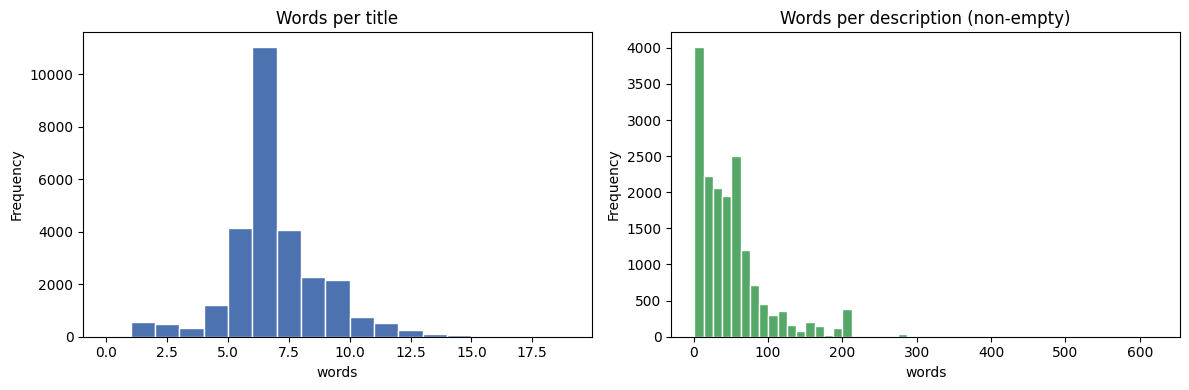

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
corpus["title_words_raw"].plot.hist(bins=range(0, 20), ax=axes[0], color="#4C72B0", edgecolor="white")
axes[0].set_title("Words per title"); axes[0].set_xlabel("words")
corpus.loc[has_desc, "desc_words_raw"].plot.hist(bins=50, ax=axes[1], color="#55A868", edgecolor="white")
axes[1].set_title("Words per description (non-empty)"); axes[1].set_xlabel("words")
savefig("word_count_distribution")

### 2.2 Average sentence length

In [26]:
from nltk.tokenize import sent_tokenize

sentences = corpus.loc[has_desc, "description"].map(lambda t: sent_tokenize(normalize_text(t)))
sent_lengths = [len(s.split()) for doc in sentences for s in doc]
print(f"Avg sentences per description: {sentences.map(len).mean():.2f}")
print(f"Avg sentence length (words)  : {np.mean(sent_lengths):.2f}")

Avg sentences per description: 3.24
Avg sentence length (words)  : 15.44


### 2.3 Vocabulary size (and most frequent terms)

In [27]:
def vocab(series):
    return collections.Counter(t for toks in series for t in toks)

raw_text = (corpus["title"].fillna("") + " " + corpus["description"].fillna("")).str.lower()
raw_vocab = collections.Counter(w for t in raw_text for w in t.split())
tok_vocab = vocab((corpus["title"].fillna("") + " " + corpus["description"].fillna("")).map(
    lambda t: tokenize(normalize_text(t))))
final_vocab = vocab(corpus["title_tokens"] + corpus["description_tokens"])
all_vocab = vocab(corpus["all_tokens"])

pd.DataFrame({"vocabulary size": [len(raw_vocab), len(tok_vocab), len(final_vocab), len(all_vocab)]},
             index=["raw (split on spaces, lowercase)", "normalized + tokenized",
                    "+ stop words removed + stemmed (title+description)",
                    "all_tokens (merged field)"])

,vocabulary size
"raw (split on spaces, lowercase)",10606
normalized + tokenized,6676
+ stop words removed + stemmed (title+description),5044
all_tokens (merged field),5790


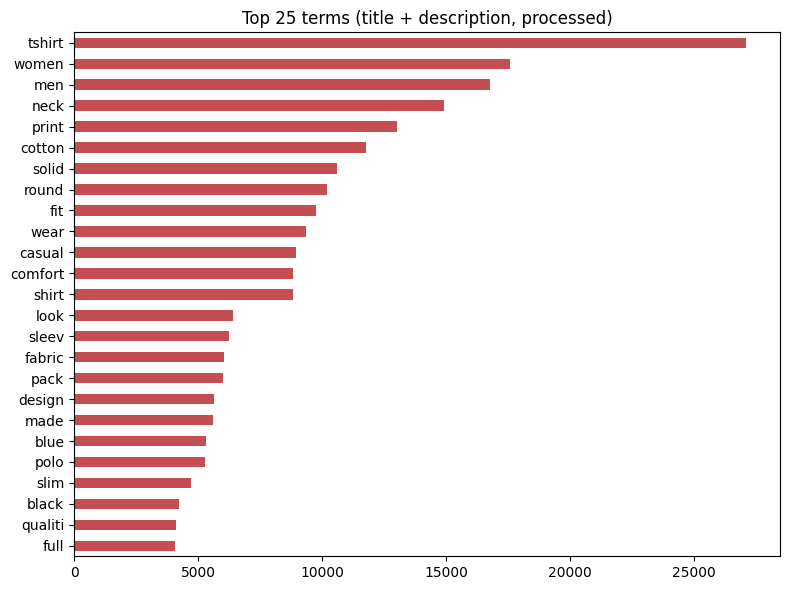

In [28]:
top = pd.Series(final_vocab).sort_values(ascending=False).head(25)
fig, ax = plt.subplots(figsize=(8, 6))
top.sort_values().plot.barh(ax=ax, color="#C44E52")
ax.set_title("Top 25 terms (title + description, processed)")
savefig("top_terms")

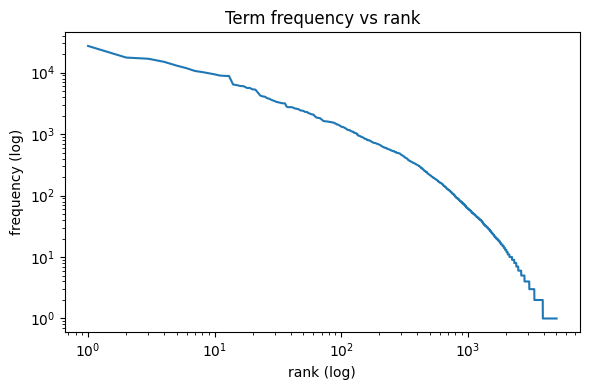

Terms that appear only once: 1123


In [29]:
# Zipf's law check
freqs = np.array(sorted(final_vocab.values(), reverse=True))
plt.figure(figsize=(6, 4))
plt.loglog(np.arange(1, len(freqs) + 1), freqs)
plt.xlabel("rank (log)"); plt.ylabel("frequency (log)"); plt.title("Term frequency vs rank")
savefig("zipf")
print("Terms that appear only once:", (freqs == 1).sum())

### 2.4 Ranking of products based on rating, price and discount

In [30]:
cols = ["pid", "title", "brand", "selling_price", "actual_price", "discount", "average_rating"]
print("Top 10 by rating (ties broken by bigger discount)")
display(corpus.sort_values(["average_rating", "discount"], ascending=False)[cols].head(10))
print("Top 10 biggest discounts")
display(corpus.sort_values("discount", ascending=False)[cols].head(10))
print("Top 10 most expensive")
display(corpus.sort_values("selling_price", ascending=False)[cols].head(10))
print("Top 10 cheapest")
display(corpus.sort_values("selling_price")[cols].head(10))

Top 10 by rating (ties broken by bigger discount)


,pid,title,brand,selling_price,actual_price,discount,average_rating
22441,KTAFAKGUKA2SXSEQ,Men Solid Cotton Blend Pathani Kurta (Blue),Purple Sta,449.0,2599.0,82.0,5.0
443,BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,249.0,1149.0,78.0,5.0
17993,TSHFNJ9ZEUZG3CPU,Printed Women Round Neck Multicolor T-Shirt,yellowvib,275.0,1200.0,77.0,5.0
18497,TSHFU5AF8KZC5FYH,Printed Women Round Neck Black T-Shirt,PixF,289.0,1299.0,77.0,5.0
18503,TSHFTT2JATXKUHEV,Solid Women Round Neck Black T-Shirt,PixF,288.0,1299.0,77.0,5.0
18543,TSHFSPXRXEFVFTXG,Solid Women Round Neck Dark Blue T-Shirt,PixF,288.0,1299.0,77.0,5.0
18714,TSHFTT2STQWNBH23,Printed Men Round Neck Blue T-Shirt,PixF,288.0,1299.0,77.0,5.0
18738,TSHFTT2JUVYZFJZY,Solid Women Round Neck Yellow T-Shirt,PixF,288.0,1299.0,77.0,5.0
18757,TSHFTT2SFXUT3N7F,Printed Women Round Neck Yellow T-Shirt,PixF,288.0,1299.0,77.0,5.0
18781,TSHFTT2SZVYFXHJV,Printed Women Round Neck Red T-Shirt,PixF,288.0,1299.0,77.0,5.0


Top 10 biggest discounts


,pid,title,brand,selling_price,actual_price,discount,average_rating
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,128.0,998.0,87.0,3.0
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,136.0,999.0,86.0,4.7
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,136.0,999.0,86.0,4.1
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt...,yellowvib,449.0,2999.0,85.0,3.2
91,CTPFVZTBN4GRZKXH,nu-Lite Satin Tie & Cufflink (Red),NaN,499.0,3299.0,84.0,2.7
18017,TSHFKHRYJYMEMZHK,Printed Men Mandarin Collar Blue T-Shirt,yellowvib,282.0,1800.0,84.0,4.2
18093,TSHFGFNBYVKZBQ2M,Printed Men Collared Neck Multicolor T-Shirt,yellowvib,230.0,1500.0,84.0,4.6
9811,CAPE9YWMSVSZPM2K,Solid Balclava Cap,Gracew,228.0,1499.0,84.0,4.3
18016,TSHFHQNCHJJUQYVQ,Printed Women Round Neck Blue T-Shirt,yellowvib,280.0,1800.0,84.0,3.4
3102,TSHFVM4PQPRY2CRZ,Color Block Women Round Neck Green T-Shirt,REF,228.0,1499.0,84.0,4.2


Top 10 most expensive


,pid,title,brand,selling_price,actual_price,discount,average_rating
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,REEB,7999.0,9999.0,20.0,2.7
11010,BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Ful...,True Bl,7998.0,7999.0,0.0,2.6
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,7799.0,12999.0,40.0,3.7
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,7799.0,12999.0,40.0,4.5
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,7794.0,12990.0,40.0,4.2
11008,BZRFVDGUJHTQHDAX,Self Design Single Breasted Party Women F...,True Bl,6998.0,6999.0,0.0,2.6
6898,JEAF8S4GE8PKH7H3,Regular Fit Men Dark Blue Cotton Blend Tr...,G,6925.0,10990.0,36.0,4.5
6901,JEAF65G3MZYG3BQM,Maxx Regular Men Black Jeans,G,6692.0,10990.0,39.0,3.8
25423,JCKFQF5K72AT2JDC,Full Sleeve Solid Women Casual Jacket,Pu,6499.0,12999.0,50.0,3.7
6855,JEAFEN3WGHH3ZEFY,Skinny Men Blue Jeans,G,6493.0,9990.0,35.0,NaN


Top 10 cheapest


,pid,title,brand,selling_price,actual_price,discount,average_rating
20435,BDAFUBD2EJHFCRNC,Men Printed Bandana,T10 Spor,99.0,199.0,50.0,2.4
16485,SOCET7QRNHYG9HHB,Women Mid-Calf/Crew (Pack of 2),Welwe,99.0,199.0,50.0,3.8
7654,SOCFFGA2FYZQBFXT,Women Color Block Ankle Length (Pack of 3),your shopping sto,118.0,499.0,76.0,3.9
24437,SOCFZAGJC3VUFQU9,Women Solid Ankle Length (Pack of 3),ina gro,120.0,399.0,69.0,NaN
24439,SOCFZ7JX39ZEW8GE,Women Solid Ankle Length (Pack of 3),ina gro,120.0,399.0,69.0,NaN
24438,SOCFZ7GFAZGYZGR7,Men Solid Ankle Length (Pack of 3),ina gro,120.0,399.0,69.0,NaN
20253,CAPEX5YHPH3MSGFC,Cotton 5 panel baseball Cap,T10 Spor,124.0,249.0,50.0,2.3
16402,SUSECSFFVNKG5VGG,Brand Trunk Y- Back Suspenders for Men (...,NaN,125.0,499.0,74.0,4.1
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,128.0,998.0,87.0,3.0
25325,SOCFPR9UF8Q4FCHG,Men Ankle Length (Pack of 3),Pu,132.0,499.0,73.0,3.7


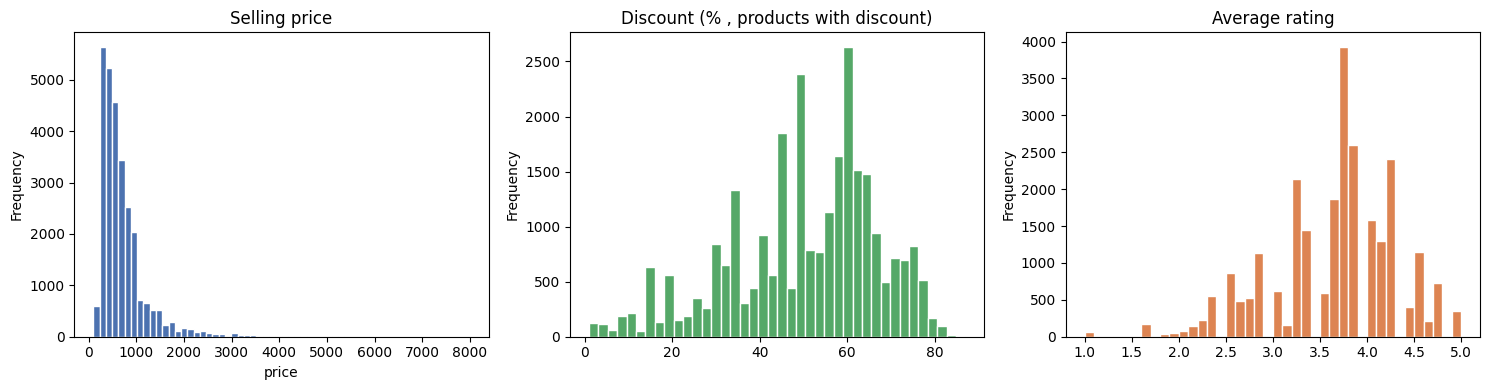

Products without rating: 2261


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
corpus["selling_price"].plot.hist(bins=60, ax=axes[0], color="#4C72B0", edgecolor="white")
axes[0].set_title("Selling price"); axes[0].set_xlabel("price")
corpus.loc[corpus["discount"] > 0, "discount"].plot.hist(bins=40, ax=axes[1], color="#55A868", edgecolor="white")
axes[1].set_title("Discount (% , products with discount)")
corpus["average_rating"].dropna().plot.hist(bins=40, ax=axes[2], color="#DD8452", edgecolor="white")
axes[2].set_title("Average rating")
savefig("numeric_distributions")
print(f"Products without rating: {(~corpus['has_rating']).sum()}")

In [32]:
corpus[["selling_price", "actual_price", "discount", "average_rating"]].corr().round(2)

,selling_price,actual_price,discount,average_rating
selling_price,1.00,0.84,-0.30,-0.01
actual_price,0.84,1.00,0.17,-0.03
discount,-0.30,0.17,1.00,-0.05
average_rating,-0.01,-0.03,-0.05,1.00


### 2.5 Top sellers and brands

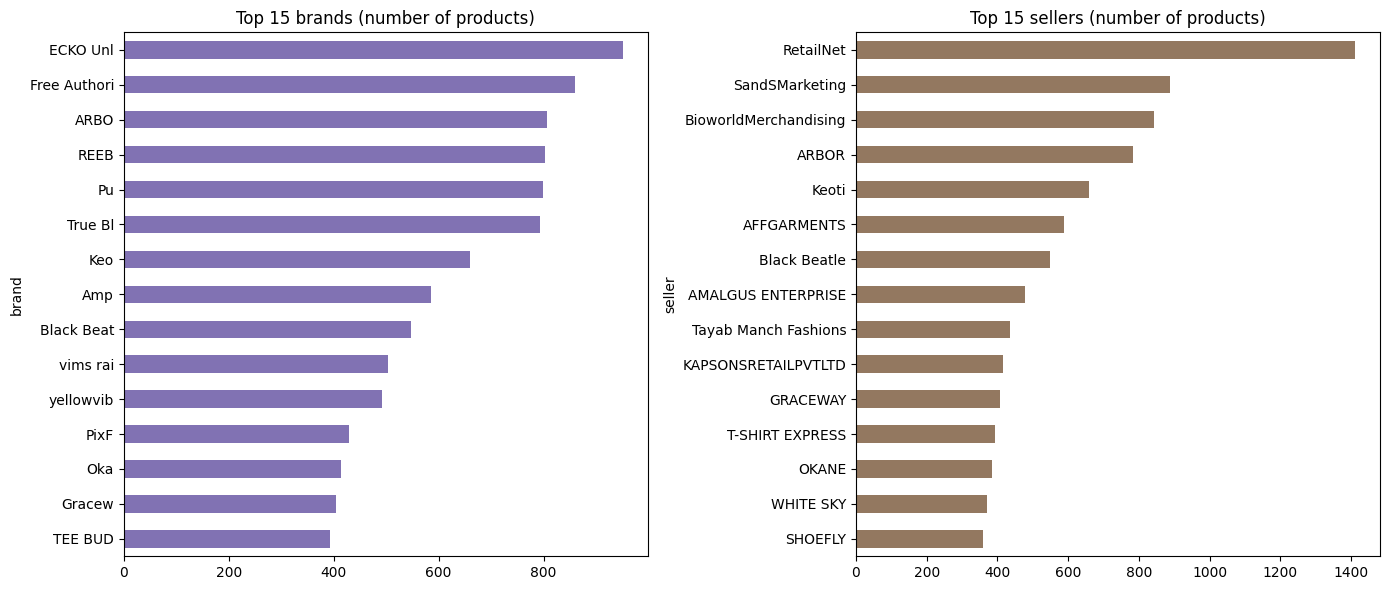

Distinct brands: 324 | distinct sellers: 534


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
corpus["brand"].value_counts().head(15).sort_values().plot.barh(ax=axes[0], color="#8172B3")
axes[0].set_title("Top 15 brands (number of products)")
corpus["seller"].value_counts().head(15).sort_values().plot.barh(ax=axes[1], color="#937860")
axes[1].set_title("Top 15 sellers (number of products)")
savefig("top_brands_sellers")
print("Distinct brands:", corpus["brand"].nunique(), "| distinct sellers:", corpus["seller"].nunique())

In [34]:
# Best rated brands (only brands with at least 50 rated products)
g = corpus.groupby("brand").agg(products=("pid", "size"), rated=("average_rating", "count"),
                                avg_rating=("average_rating", "mean"), avg_price=("selling_price", "mean"),
                                avg_discount=("discount", "mean"))
g[g["rated"] >= 50].sort_values("avg_rating", ascending=False).round(2).head(10)

,products,rated,avg_rating,avg_price,avg_discount
brand,,,,,
SORA,74,74,4.61,694.19,61.50
PixF,429,328,4.46,305.03,76.03
Cots,277,277,4.44,356.88,39.19
Zack Fo,128,128,4.33,571.20,62.27
Onei,57,57,4.23,520.74,62.67
Gracew,405,404,4.23,412.07,57.31
Marca Disa,353,334,4.19,582.79,43.60
REEBOK CLASSI,75,75,4.14,1723.51,44.25
Byford by Pantaloo,179,177,4.11,736.54,14.55


In [35]:
# Truncated brand names: brand is often a prefix of the seller name
same_prefix = corpus.dropna(subset=["brand", "seller"])
same_prefix = same_prefix[same_prefix.apply(
    lambda r: r["seller"].lower().startswith(r["brand"].lower()) and len(r["seller"]) > len(r["brand"]), axis=1)]
print(f"{len(same_prefix)} products where brand is a truncated prefix of seller, e.g.:")
same_prefix[["brand", "seller"]].drop_duplicates().head(10)

8414 products where brand is a truncated prefix of seller, e.g.:


,brand,seller
333,SayItLo,sayitloud
910,SMART ATTRACTI,SMART ATTRACTION
1156,Clo,Clodz
1218,CA,caratrend
1479,K M,K M R GARMENTS
1561,wangjia,WANGJIANG IND
2714,PIS,Pison(Not Enough Ratin
2716,Platin,PLATINUM retails
2726,INTER CREATI,INTER CREATION
3791,limited colou,Limited colours


### 2.6 Out-of-stock distribution

out_of_stock
False    0.941
True     0.059
Name: proportion, dtype: float64


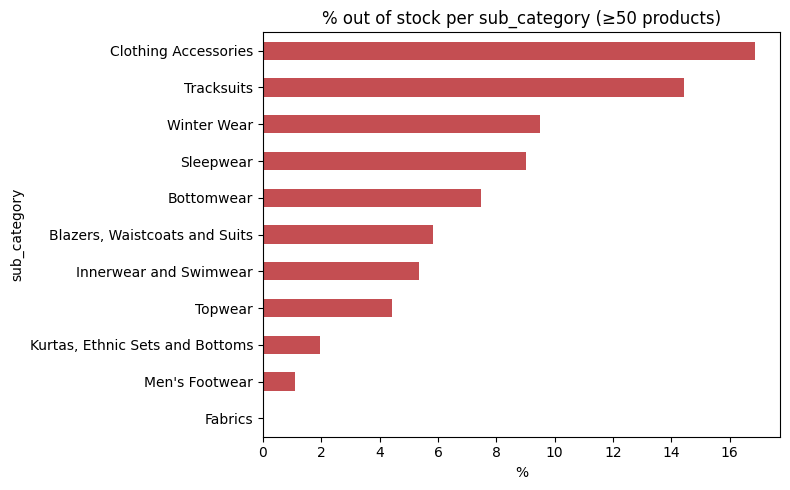

In [36]:
print(corpus["out_of_stock"].value_counts(normalize=True).round(3))
oos = corpus.groupby("sub_category")["out_of_stock"].agg(["mean", "size"])
oos = oos[oos["size"] >= 50].sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 5))
(oos["mean"] * 100).plot.barh(ax=ax, color="#C44E52")
ax.set_title("% out of stock per sub_category (≥50 products)"); ax.set_xlabel("%")
savefig("out_of_stock")

### 2.7 Word clouds for the most frequent words

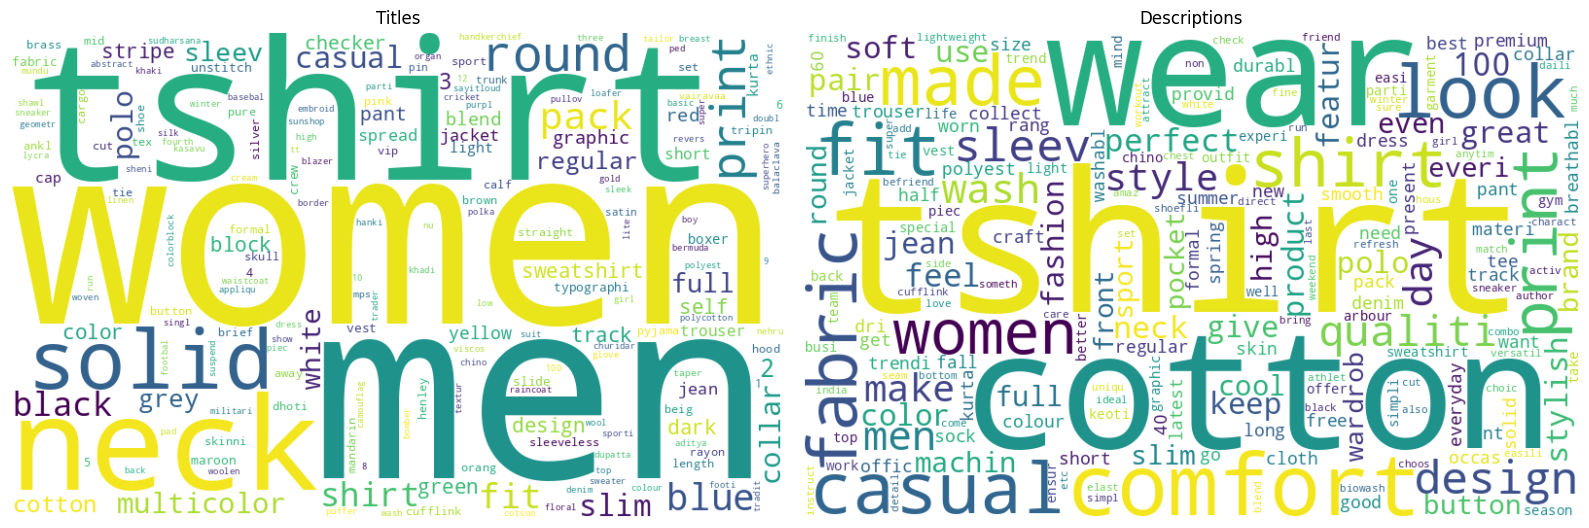

In [37]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, title in [(axes[0], "title_tokens", "Titles"), (axes[1], "description_tokens", "Descriptions")]:
    wc = WordCloud(width=800, height=500, background_color="white", random_state=0)
    wc.generate_from_frequencies(vocab(corpus[col]))
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(title)
savefig("wordclouds")

### 2.8 Entity recognition

We use spaCy's small English model on a random sample of **original** (not lowercased) descriptions (running it on all 17k
descriptions is slow). The model is trained on news text, so on product descriptions it mostly
finds brand names (ORG), places (GPE, e.g. "India") and numbers/percentages – and makes mistakes
on fashion vocabulary. Install the model once with `python -m spacy download en_core_web_sm`.

In [38]:
try:
    import spacy
    nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
except (ImportError, OSError) as e:
    nlp = None
    print("spaCy model not available:", e)

if nlp is not None:
    sample = corpus.loc[has_desc, "description"].sample(2000, random_state=42).map(
        lambda t: re.sub(r"([a-z])([.,])([A-Z])", r"\1\2 \3", html.unescape(t)))  # keep original case: NER relies on capitals
    ents = [(ent.text.strip(), ent.label_) for doc in nlp.pipe(sample, batch_size=200) for ent in doc.ents]
    ent_df = pd.DataFrame(ents, columns=["entity", "label"])
    print("Entities found:", len(ent_df))
    display(ent_df["label"].value_counts().head(10))
    for lab in ["ORG", "GPE", "PERSON", "CARDINAL"]:
        print(lab, "->", ent_df[ent_df.label == lab]["entity"].value_counts().head(10).to_dict())

Entities found: 5578


label
ORG            1668
PERSON         1121
PERCENT         673
DATE            647
GPE             451
CARDINAL        413
WORK_OF_ART     201
NORP            198
PRODUCT          61
QUANTITY         33
Name: count, dtype: int64

ORG -> {'Printed': 45, 'Round Neck Tees': 34, 'KEOTI': 33, 'Tshirt': 31, 'THE AMAZING COMFORT OF A Shoefly POLO T-SHIRTS': 27, 'THE AMAZING COMFORT OF A KEOTI POLO T-SHIRTS': 26, 'Half & Full Sleeve': 23, 'XXL': 22, 'Girls': 21, 'Polo T-Shirts': 20}
GPE -> {'Cotton': 104, 'kurta': 49, 'India': 43, 'Kurta': 32, 'Ladies': 25, 'INDIA': 23, 'Solid': 21, 'Sweatshirt': 15, 'Shoefly': 11, 'Ldhsati': 11}
PERSON -> {'Casual Wear': 50, 'Track Pant': 48, 'Cotton': 41, 'Lucky Bird': 38, 'Arbour': 37, 'Denims': 36, 'Cotton Fabric': 31, 'Casual': 27, 'Sweatshirts': 24, 'Levis': 21}
CARDINAL -> {'half': 50, '3': 49, '2': 33, 'one': 26, 'two': 26, 'One': 22, '5': 18, '4': 16, '180': 12, 'Two': 11}


### 2.9 Other findings
Extra analyses not in the statement's list: category distribution and duplicated products.

category
Clothing and Accessories    27118
Footwear                      920
Bags, Wallets & Belts          41
Toys                            1
Name: count, dtype: int64 



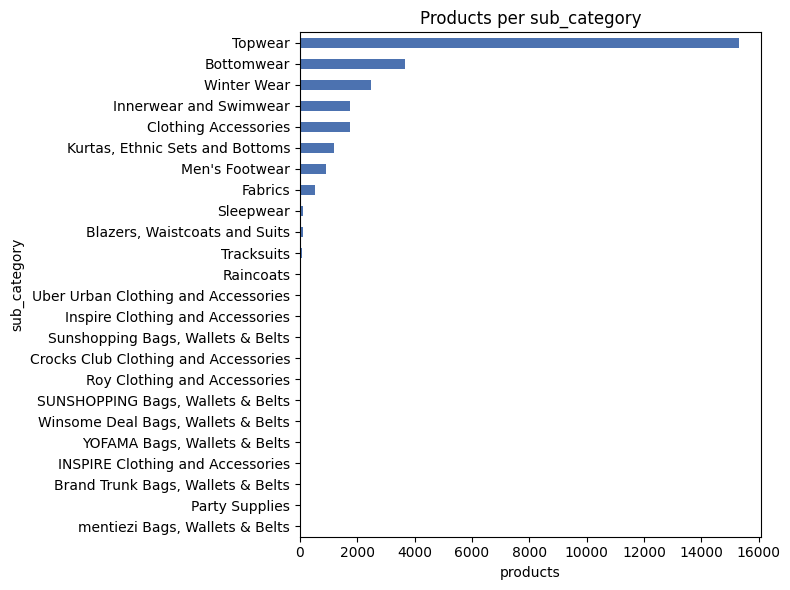

In [39]:
print(corpus["category"].value_counts(), "\n")
fig, ax = plt.subplots(figsize=(8, 6))
corpus["sub_category"].value_counts().sort_values().plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Products per sub_category"); ax.set_xlabel("products")
savefig("sub_category")

In [40]:
print("Distinct titles      :", corpus["title"].nunique())
print("Distinct descriptions:", corpus["description"].nunique())
dup = corpus.duplicated(subset=["title", "description", "brand", "selling_price"], keep=False)
print(f"Products sharing title+description+brand+price with another product: {dup.sum()} ({dup.mean():.1%})")
corpus["title"].value_counts().head(10)

Distinct titles      : 5953
Distinct descriptions: 5683
Products sharing title+description+brand+price with another product: 11816 (42.1%)


title
Slides                                      544
Printed Men Round Neck Black T-Shirt        418
Printed Women Round Neck Black T-Shirt      396
Printed Women Round Neck White T-Shirt      349
Rayon Printed Shirt Fabric  (Unstitched)    343
Printed Men Round Neck White T-Shirt        323
Full Sleeve Solid Men Sweatshirt            214
Full Sleeve Solid Women Sweatshirt          204
Printed Women Round Neck Blue T-Shirt       189
Full Sleeve Printed Men Sweatshirt          184
Name: count, dtype: int64

### 2.10 Summary of findings

> ✏️ *Group: write here (and in the report) the main conclusions in your own words, e.g. missing
> descriptions, near-duplicate titles, unbalanced categories, truncated brands, rating/price
> distributions, and how they influence the indexing and ranking decisions for Part 2 and 3.*